# EDA figures for the midterm report

This notebook makes the three figures in the EDA section of the report.


In [1]:
#import packages
import pandas as pd
import numpy as np
import matplotlib
from matplotlib import pylab as plt

In [2]:
# read the training set, the validation set (2023) and the test set (2024)
df = pd.read_csv('../data/hmda_train.csv')
val = pd.read_csv('../data/hmda_validation.csv')
test = pd.read_csv('../data/hmda_test_2024.csv')
print(df.shape)
print(val.shape)
print(test.shape)

(65978, 11)
(10630, 11)
(11676, 11)


In [3]:
# dti bins and missing-value flags
# dti is a range at both ends and a single number in between, so replace each range by a number inside it
dti_ranges = {'<20%': 15, '20%-<30%': 25, '30%-<36%': 33, '50%-60%': 55, '>60%': 65}
dti_order = ['<20%', '20-30%', '30-36%', '36-43%', '43-50%', '50-60%', '>60%']

for d in [df, val, test]:
    d['dti'] = pd.to_numeric(d['debt_to_income_ratio'], errors='coerce')
    d['dti'] = d['dti'].fillna(d['debt_to_income_ratio'].map(dti_ranges))
    d['dti_bin'] = pd.cut(d['dti'], bins=[0, 20, 30, 36, 43, 50, 60, 100], right=False, labels=dti_order)
    d['income_missing'] = d['income'].isna().astype(int)
    d['property_value_missing'] = d['property_value'].isna().astype(int)
    d['loan_to_value_ratio_missing'] = d['loan_to_value_ratio'].isna().astype(int)
    d['dti_missing'] = d['dti'].isna().astype(int)

## Figure 1: denial rate by DTI

In [4]:
#fraction denied in each dti bin
# reindex them in the correct order
dti_order = ['<20%', '20-30%', '30-36%', '36-43%', '43-50%', '50-60%', '>60%']
rate_by_dti = df.groupby('dti_bin', observed=True)['denied'].mean().reindex(dti_order)
print(rate_by_dti)
print('all applications:', df['denied'].mean())

# same pattern in 2023
print(val.groupby('dti_bin', observed=True)['denied'].mean().reindex(dti_order))

dti_bin
<20%      0.087657
20-30%    0.050607
30-36%    0.052509
36-43%    0.055143
43-50%    0.071420
50-60%    0.157236
>60%      0.790399
Name: denied, dtype: float64
all applications: 0.09406165691594168
dti_bin
<20%      0.080488
20-30%    0.052042
30-36%    0.056047
36-43%    0.046717
43-50%    0.066086
50-60%    0.140693
>60%      0.844193
Name: denied, dtype: float64


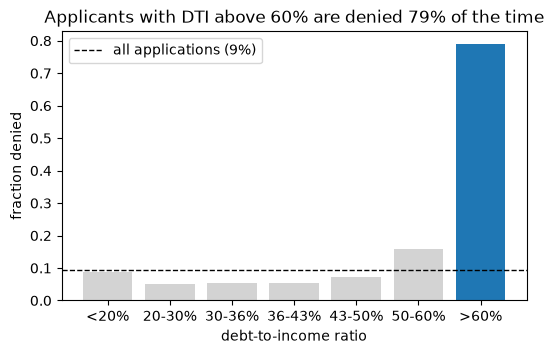

In [5]:
# highlight the >60% bin in blue
colors = ['lightgray', 'lightgray', 'lightgray', 'lightgray', 'lightgray', 'lightgray', 'tab:blue']

plt.figure(figsize=(6,3.5))
plt.bar(dti_order, rate_by_dti.values, color=colors)
# dashed line is denial rate of all training applications
plt.axhline(df['denied'].mean(), color='black', linestyle='--', linewidth=1, label='all applications (9%)')
plt.xlabel('debt-to-income ratio')
plt.ylabel('fraction denied')
plt.legend(loc='upper left')
plt.title('Applicants with DTI above 60% are denied 79% of the time')
plt.savefig('../figures/fig1_denial_by_dti.png', dpi=150, bbox_inches='tight')
plt.show()

## Figure 2: denial rate when a value is missing

These are raw rates. The last table checks whether the property value gap is still there within each DTI bin.

In [6]:
#  fraction denied when each value is reported or missing
flags = ['income_missing', 'property_value_missing', 'loan_to_value_ratio_missing', 'dti_missing']
rates = pd.DataFrame()
for f in flags:
    rates[f] = df.groupby(f)['denied'].mean()
rates = rates.T
rates.columns = ['value reported', 'value missing']
print(rates)

#number of applications with each value missing
print(df[flags].sum())

#fraction denied with and without a property value
print(df.groupby(['dti_bin', 'property_value_missing'], observed=True)['denied'].mean().unstack().reindex(dti_order))

                             value reported  value missing
income_missing                     0.093754       0.105826
property_value_missing             0.084635       0.519580
loan_to_value_ratio_missing        0.085264       0.319226
dti_missing                        0.088646       0.237599
income_missing                 1682
property_value_missing         1430
loan_to_value_ratio_missing    2481
dti_missing                    2399
dtype: int64
property_value_missing         0         1
dti_bin                                   
<20%                    0.082223  0.730769
20-30%                  0.047801  0.805556
30-36%                  0.050132  0.781250
36-43%                  0.053000  0.740000
43-50%                  0.067776  0.940299
50-60%                  0.147261  1.000000
>60%                    0.774545  1.000000


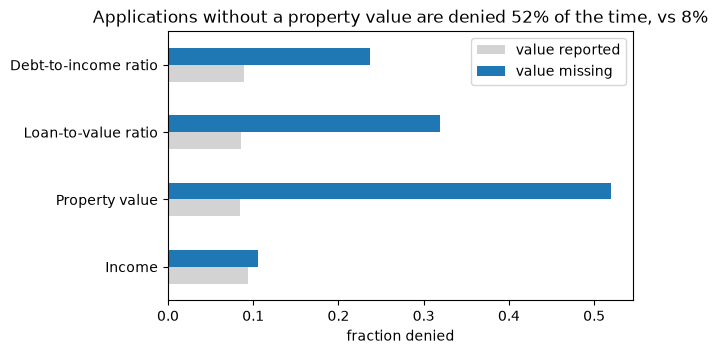

In [7]:
rates.index = ['Income', 'Property value', 'Loan-to-value ratio', 'Debt-to-income ratio']

rates.plot.barh(figsize=(6,3.5), color=['lightgray', 'tab:blue'])
plt.xlabel('fraction denied')
plt.ylabel('')
plt.title('Applications without a property value are denied 52% of the time, vs 8%')
plt.savefig('../figures/fig2_missing_values.png', dpi=150, bbox_inches='tight')
plt.show()

## Figure 3: loan amounts in the training years, 2023 and 2024

Only the features of 2024 are used here, not the labels.

In [8]:
# denial rate in the training set and in 2023
print('train:', df['denied'].mean())
print('2023:', val['denied'].mean())

# median loan amounts and income
print(df['loan_amount'].median(), val['loan_amount'].median(), test['loan_amount'].median())
print(df['income'].median(), val['income'].median(), test['income'].median())

print((df['dti_bin'] == '43-50%').sum() / df['dti_bin'].notna().sum())
print((val['dti_bin'] == '43-50%').sum() / val['dti_bin'].notna().sum())
print((test['dti_bin'] == '43-50%').sum() / test['dti_bin'].notna().sum())

train: 0.09406165691594168
2023: 0.09915333960489181
275000.0 355000.0 375000.0
86.0 114.0 121.0
0.25237893014989227
0.30637037037037035
0.3299359610354469


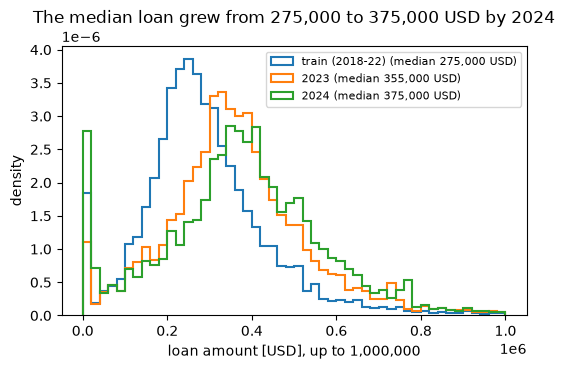

In [9]:
groups = [df, val, test]
labels = ['train (2018-22) (median 275,000 USD)', '2023 (median 355,000 USD)', '2024 (median 375,000 USD)']
bins = np.arange(0, 1000001, 20000)

plt.figure(figsize=(6,3.5))
for i in range(3):
    plt.hist(groups[i]['loan_amount'], bins=bins, density=True, histtype='step', linewidth=1.5, label=labels[i])
plt.legend(loc='upper right', fontsize=8)
plt.xlabel('loan amount [USD], up to 1,000,000')
plt.ylabel('density')
plt.title('The median loan grew from 275,000 to 375,000 USD by 2024')
plt.savefig('../figures/fig3a_drift_loan_amount.png', dpi=150, bbox_inches='tight')
plt.show()